# Temat podstawowy - Klasyfikacji tekstu na wybranym zbiorze danych

Zaimplementowanie i eksperymentalne porównanie skuteczności trzech podejść:

1. Ekstrakcja cech z tekstu metodami klasycznymi, np. TF-IDF lub BM25. Metoda uczenia maszynowego oparta o tak wyznaczone reprezentacje uczona na zbiorze treningowym.

2. Klasyfikator probabilistyczny oparty o wybrany model klasy tylko-koder dostrojony na zbiorze treningowym.  

3. Dostosowanie modelu generatywnego (klasy tylko-dekoder) do generowania odpowiedzi w oczekiwanym formacie. Np. w klasyfikatorze spamu generowania tokenów „tak” lub „nie”. Sprawdzenie metody few-shot prompting (in-context learning) oraz wybranej metody  efektywnego dostrajania modelu (metody rodziny PeFT),  np. soft-prompt tuning czy LoRA.

**Dla każdego podejścia**

- Wyznaczenie metryk takich, jak dokładność, precyzja i czułość dla każdej klasy, macierz pomyłek na zbiorze treningowym i testowym.

- Wizualizacja wyznaczonych reprezentacji (dla części zbioru testowego) metodą tSNE lub UMAP.

## Instalacja bibliotek, importy, ustawienie wandb

In [1]:
!pip install -q umap-learn tqdm lightning wandb torchmetrics evaluate colorama bitsandbytes accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 26.9 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
from tqdm import tqdm

In [ ]:
import wandb
wandb.login()

In [4]:
%env WANDB_PROJECT=LLM_PROJECT

env: WANDB_PROJECT=LLM_PROJECT


## Załadowanie zbioru danych

In [5]:
from datasets import load_dataset
ds = load_dataset("dair-ai/emotion", "split")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

split/train-00000-of-00001.parquet:   0%|          | 0.00/1.03M [00:00<?, ?B/s]

split/validation-00000-of-00001.parquet:   0%|          | 0.00/127k [00:00<?, ?B/s]

split/test-00000-of-00001.parquet:   0%|          | 0.00/129k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [6]:
print(ds.column_names)
print(ds.num_rows)

{'train': ['text', 'label'], 'validation': ['text', 'label'], 'test': ['text', 'label']}
{'train': 16000, 'validation': 2000, 'test': 2000}


In [7]:
example_data = ds["train"][0]
print(example_data)

{'text': 'i didnt feel humiliated', 'label': 0}


In [8]:
train_dataset = ds["train"]
val_dataset = ds["validation"]
test_dataset = ds["test"]
NUM_LABELS = 6
LABELS = ["sadness", "joy", "love", "anger", "fear", "surprise"]
LABELS_WITH_NUMS = ["sadness (0)", "joy (1)", "love (2)", "anger (3)", "fear (4)", "surprise (5)"]
LABEL_MAP = {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}

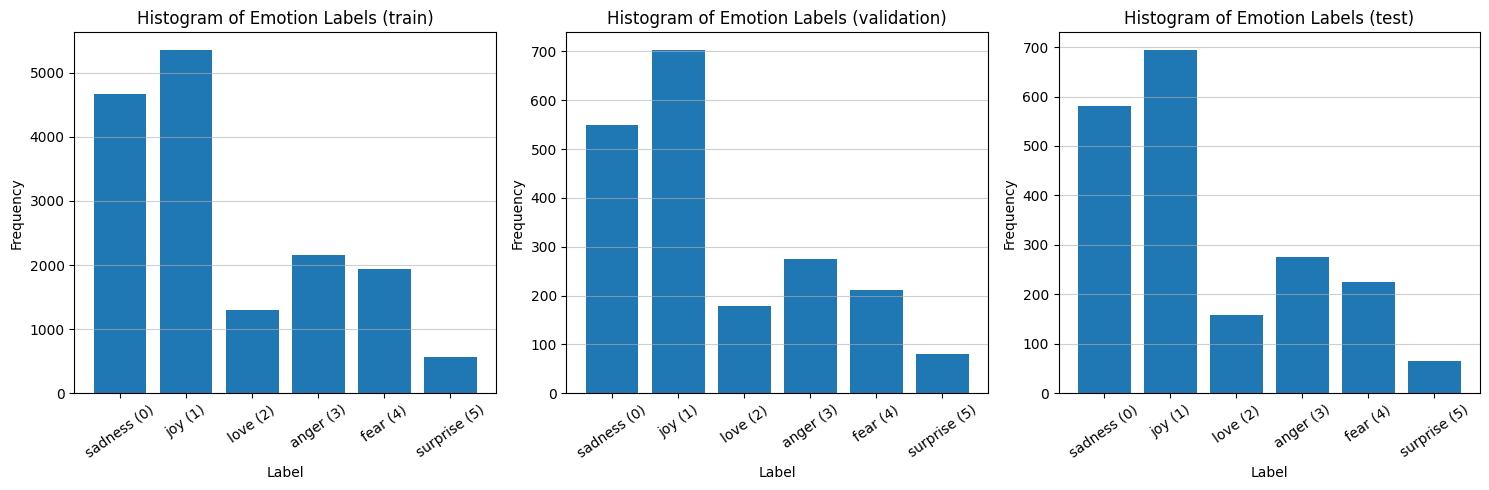

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, split in enumerate(ds.column_names.keys()):
    unique_labels, counts = np.unique(ds[split]["label"], return_counts=True)
    axs[i].bar(unique_labels, counts)
    axs[i].set_title(f'Histogram of Emotion Labels ({split})')
    axs[i].set_xlabel('Label')
    axs[i].set_ylabel('Frequency')
    axs[i].set_xticks(ticks=unique_labels, labels=LABELS_WITH_NUMS, rotation=35)
    axs[i].grid(axis='y', alpha=0.6)
plt.tight_layout()
plt.show()

## Funkcje pomocnicze

In [20]:
from sklearn.metrics import classification_report
def print_classification_report(targets, preds):
    report = classification_report(targets, preds, target_names = LABELS_WITH_NUMS)
    print(report)

In [21]:
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(targets, preds, title='Macierz pomyłek'):
    cm = confusion_matrix(targets, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
    plt.title(title)
    plt.xlabel('Predykowana klasa')
    plt.ylabel('Prawdziwa klasa')
    plt.show()


In [22]:
import umap
def gen_df_umap(features, labels) -> pd.DataFrame:
    reducer = umap.UMAP()
    embeddings = reducer.fit_transform(features)
    df_umap = pd.DataFrame({
        'UMAP X': embeddings[:, 0],
        'UMAP Y': embeddings[:, 1],
        'Klasa': labels
    })
    return df_umap


In [23]:
def plot_umap(df_umap: pd.DataFrame, title: str):
    df_umap['Klasa'] = df_umap['Klasa'].map(LABEL_MAP)
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=df_umap,
        x='UMAP X',
        y='UMAP Y',
        hue='Klasa',
        palette='bright',
        alpha=0.7
    )
    plt.title(title, fontsize=14)
    plt.legend(title='Etykieta')
    plt.show()

## Podejście 1 - Ekstrakcja cech metodami klasycznymi + Sieć Neuronowa

### Ekstrakcja cech

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
VOCAB_SIZE=10000

vectorizer = TfidfVectorizer(
    max_features=VOCAB_SIZE,
    lowercase=True,
    analyzer='word',
    ngram_range=(1,2),
    stop_words="english"
)

train_tfidf_features = vectorizer.fit_transform(ds["train"]["text"])
val_tfidf_features = vectorizer.transform(ds["validation"]["text"])
test_tfidf_features = vectorizer.transform(ds["test"]["text"])
tfidf_features_map = {"train": train_tfidf_features, "validation": val_tfidf_features, "test": test_tfidf_features}

In [35]:
feature_names = vectorizer.get_feature_names_out()
print(f"Przykładowe cechy: {np.random.choice(feature_names, 20)}\n")

Przykładowe cechy: ['know want' 'deserve punished' 'lines' 'delicate' 'wife feel' 'yall'
 'teenager' 'visited' 'url' 'dinner' 'little disappointed' 'feel ive'
 'spouse' 'feel like' 'quicker' 'works' 'answered' 'gates' 'hardly'
 'try try']



In [36]:
ndx = 20
print(f"Element zbioru treningowego o indeksie={ndx}")
print(f"{ds["train"]["text"][ndx]=}\n")
features = train_tfidf_features[ndx]
print(f"Cechy elementu o indeksie={ndx}:")
non_zero_cols = features.nonzero()[1]

non_zero_cols = sorted(non_zero_cols)
for i in non_zero_cols:
    print(f"Kolumna: {i} ({feature_names[i]})   Waga: {features[0, i]:.5f}")

Element zbioru treningowego o indeksie=20
ds["train"]["text"][ndx]='i feel irritated and rejected without anyone doing anything or saying anything'

Cechy elementu o indeksie=20:
Kolumna: 1881 (doing)   Waga: 0.36293
Kolumna: 2344 (feel)   Waga: 0.09803
Kolumna: 2604 (feel irritated)   Waga: 0.51123
Kolumna: 4565 (irritated)   Waga: 0.45264
Kolumna: 7869 (rejected)   Waga: 0.45482
Kolumna: 8136 (saying)   Waga: 0.43078


Średnia liczba niezerowych cech w próbkach: 9.57
Średnia liczba słów w tekście w zbiorze treningowym: 19.17



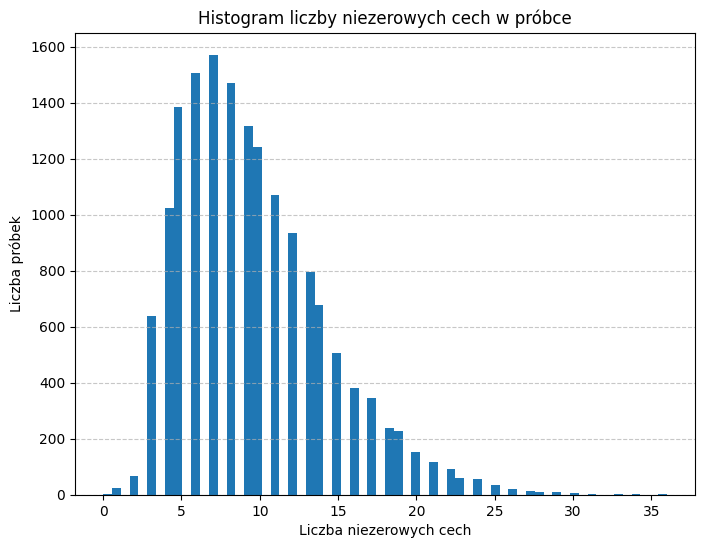

In [37]:
non_zero_counts = np.diff(train_tfidf_features.indptr)
print(f"Średnia liczba niezerowych cech w próbkach: {non_zero_counts.mean():.2f}")

text_lengths = [len(x.split()) for x in ds["train"]["text"]]
print(f"Średnia liczba słów w tekście w zbiorze treningowym: {np.mean(text_lengths):.2f}\n")

plt.figure(figsize=(8, 6))
plt.hist(non_zero_counts, bins=64)
plt.title('Histogram liczby niezerowych cech w próbce')
plt.xlabel('Liczba niezerowych cech')
plt.ylabel('Liczba próbek')
plt.grid(axis='y', linestyle='--', alpha=0.7)

### Przygotowanie danych

In [38]:
from scipy.sparse import csr_matrix
from datasets import Dataset
from torch.utils.data import TensorDataset, DataLoader

def create_dataloader(dataset: Dataset, sparse_features: csr_matrix, shuffle: bool) -> dict[str, DataLoader]:
    dense_features = sparse_features.astype(np.float32).todense()
    tdataset = TensorDataset(torch.from_numpy(dense_features), torch.tensor(dataset["label"], dtype=torch.int64))
    return DataLoader(tdataset, batch_size=256, shuffle=shuffle, num_workers=0)

dataloaders = {key: create_dataloader(ds[key], tfidf_features_map[key], shuffle=key=="train") for key in ds.column_names.keys()}


### Utworzenie modelu sieci neuronowej

In [39]:
import torch.nn as nn

class EmotionNet(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU()
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(16, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits

    def get_features(self, x: torch.Tensor) -> torch.Tensor:
        return self.feature_extractor(x)

In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [41]:
classifier = EmotionNet(VOCAB_SIZE, n_classes=NUM_LABELS)
classifier.to(device)
print(classifier)

EmotionNet(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=16, bias=True)
    (3): ReLU()
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=6, bias=True)
)


### Trening

In [42]:
import lightning as L
import torchmetrics


class LitNet(L.LightningModule):
    def __init__(self, classifier: nn.Module, max_epochs: int = 100):
        super().__init__()
        self.classifier = classifier
        self.max_epochs = max_epochs
        self.criterion = nn.CrossEntropyLoss()

        self.metric_train_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=NUM_LABELS)
        self.metric_val_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=NUM_LABELS)
        self.metric_test_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=NUM_LABELS)

    def training_step(self, batch, batch_idx):
        x, target = batch
        logits = self.classifier(x)
        loss = self.criterion(logits, target)
        self.log("train/loss", loss, prog_bar=True)

        _, preds = torch.max(logits, dim=1)
        self.metric_train_acc(preds, target)
        self.log('train/accuracy', self.metric_train_acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, target = batch
        logits = self.classifier(x)
        loss = self.criterion(logits, target)
        self.log("val/loss", loss, prog_bar=True)

        _, preds = torch.max(logits, dim=1)
        self.metric_val_acc(preds, target)
        self.log('val/accuracy', self.metric_val_acc, on_step=False, on_epoch=True, prog_bar=True)

    def test_step(self, batch, batch_idx):
        x, target = batch
        logits = self.classifier(x)

        _, preds = torch.max(logits, dim=1)
        self.metric_test_acc(preds, target)
        self.log('test/accuracy', self.metric_test_acc, on_step=False, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.classifier.parameters(), lr=1e-4, weight_decay=1e-5)
        lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.max_epochs, eta_min=1e-5)
        return {"optimizer": optimizer,"lr_scheduler": lr_scheduler}

In [43]:
MAX_EPOCHS = 120
lit_model = LitNet(classifier, max_epochs=MAX_EPOCHS)

In [44]:
from lightning.pytorch.loggers import WandbLogger
wandb_logger = WandbLogger(project="LLM_PROJECT")
trainer = L.Trainer(max_epochs=MAX_EPOCHS, logger=wandb_logger)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [45]:
trainer.fit(
    lit_model,
    train_dataloaders=dataloaders["train"],
    val_dataloaders=dataloaders["validation"]
    )

INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/loggers/wandb.py:400: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ classifier       │ EmotionNet         │  641 K │ train │     0 │
│ 1 │ criterion        │ CrossEntropyLoss   │      0 │ train │     0 │
│ 2 │ metric_train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ metric_val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 4 │ metric_test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴──────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 641 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 641 K                                                                                                
Total estimated model params size (MB): 2                                                                          
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=120` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=120` reached.


In [46]:
trainer.test(ckpt_path="best", dataloaders=dataloaders["test"])

INFO: Restoring states from the checkpoint path at ./LLM_PROJECT/pm2m9cs0/checkpoints/epoch=119-step=7560.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at ./LLM_PROJECT/pm2m9cs0/checkpoints/epoch=119-step=7560.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at ./LLM_PROJECT/pm2m9cs0/checkpoints/epoch=119-step=7560.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at ./LLM_PROJECT/pm2m9cs0/checkpoints/epoch=119-step=7560.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/accuracy       │    0.8634999990463257     │
└───────────────────────────┴───────────────────────────┘

[{'test/accuracy': 0.8634999990463257}]

In [ ]:
wandb_logger.experiment.finish()

### Wyznaczenie metryk

In [48]:
def get_preds_and_targets_tfidf(split):
    preds_all = []
    targets_all = []

    classifier.eval()
    classifier.to(device)
    for X_batch, target in tqdm(dataloaders[split]):
        X_batch, target = X_batch.to(device), target.to(device)

        with torch.inference_mode():
            logits = classifier(X_batch)
            _, preds = torch.max(logits, dim=-1)
            preds_all.extend(preds.cpu().numpy())
            targets_all.extend(target.cpu().numpy())

    preds = np.array(preds_all)
    targets = np.array(targets_all)
    return preds, targets

#### Na zbiorze testowym

In [49]:
preds, targets = get_preds_and_targets_tfidf("test")

100%|██████████| 8/8 [00:00<00:00, 129.60it/s]


In [50]:
print_classification_report(targets, preds)

              precision    recall  f1-score   support

 sadness (0)       0.88      0.94      0.91       581
     joy (1)       0.89      0.92      0.91       695
    love (2)       0.66      0.70      0.68       159
   anger (3)       0.89      0.84      0.86       275
    fear (4)       0.85      0.86      0.86       224
surprise (5)       1.00      0.06      0.11        66

    accuracy                           0.86      2000
   macro avg       0.86      0.72      0.72      2000
weighted avg       0.87      0.86      0.85      2000



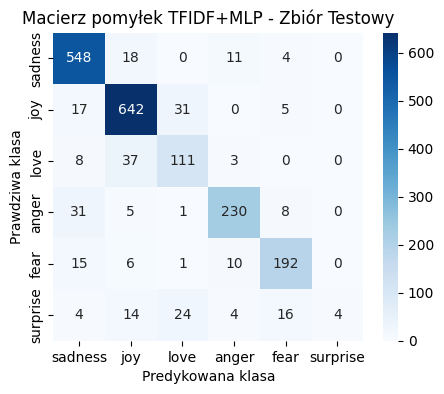

In [51]:
plot_confusion_matrix(targets, preds, title="Macierz pomyłek TFIDF+MLP - Zbiór Testowy")


#### Na zbiorze treningowym

In [52]:
preds, targets = get_preds_and_targets_tfidf("train")

100%|██████████| 63/63 [00:00<00:00, 124.53it/s]


In [53]:
print_classification_report(targets, preds)

              precision    recall  f1-score   support

 sadness (0)       0.99      0.99      0.99      4666
     joy (1)       0.99      0.99      0.99      5362
    love (2)       0.74      0.97      0.84      1304
   anger (3)       0.97      0.98      0.98      2159
    fear (4)       0.96      0.98      0.97      1937
surprise (5)       1.00      0.10      0.18       572

    accuracy                           0.95     16000
   macro avg       0.94      0.83      0.82     16000
weighted avg       0.96      0.95      0.94     16000



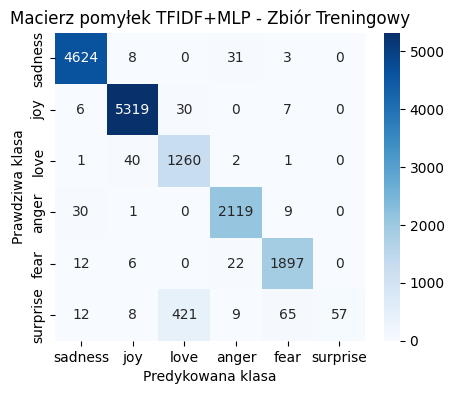

In [54]:
plot_confusion_matrix(targets, preds, title="Macierz pomyłek TFIDF+MLP - Zbiór Treningowy")

### Wizualizacja wyznaczonych reprezentacji (dla części zbioru testowego) metodą UMAP.

In [55]:
features_labels = np.array(ds["test"]["label"])
test_features = []

classifier.eval()
classifier.to(device)

for X_batch, target in tqdm(dataloaders['test']):
    X_batch, target = X_batch.to(device), target.to(device)

    with torch.inference_mode():
        f = classifier.get_features(X_batch)
        test_features.extend(f.cpu().numpy())

df_umap = gen_df_umap(test_features, features_labels)

100%|██████████| 8/8 [00:00<00:00, 150.52it/s]


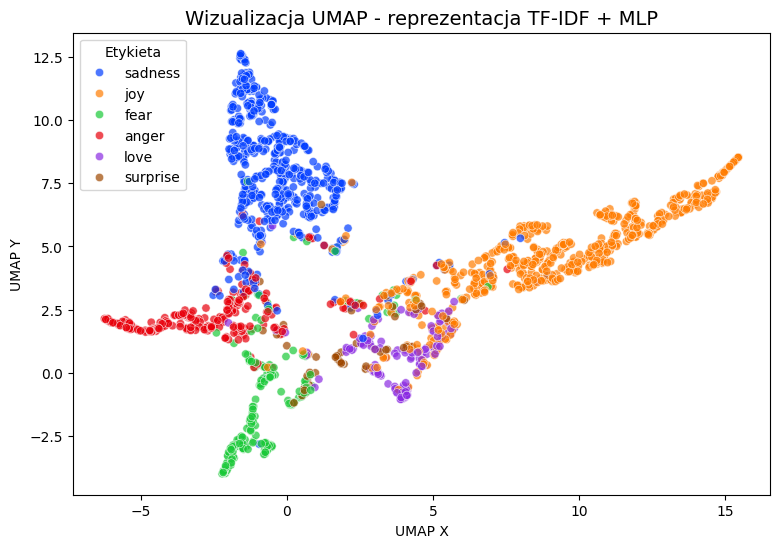

In [56]:
plot_umap(df_umap, "Wizualizacja UMAP - reprezentacja TF-IDF + MLP")

## Podejście 2 - Klasyfikator probabilistyczny oparty o wybrany model klasy tylko-koder dostrojony na zbiorze treningowym.  

### Tokenizacja danych

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=512)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [11]:
tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
tokenized_test_dataset = test_dataset.map(tokenize_function, batched=True)

print(tokenized_train_dataset)
print(tokenized_test_dataset)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 16000
})
Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 2000
})


### Dostrajanie pre-trenowanego modelu DistilBERT

In [12]:
from transformers import AutoModelForSequenceClassification

dbert_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=NUM_LABELS)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dbert_model.to(device)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [14]:
from transformers import TrainingArguments

training_args = TrainingArguments(output_dir="dbert_trainer", eval_strategy="steps", report_to="wandb",
                                  per_device_eval_batch_size=32, per_device_train_batch_size=32,
                                  logging_steps=200, fp16=True, num_train_epochs=2)

In [15]:
from evaluate import load

metric = load("accuracy")

def compute_metrics(eval_pred):
  logits, labels = eval_pred
  predictions = np.argmax(logits, axis=-1)
  return metric.compute(predictions=predictions, references=labels)


In [16]:
from transformers import Trainer

trainer = Trainer(
    model=dbert_model,
    args=training_args,
    train_dataset=tokenized_train_dataset,
    eval_dataset=tokenized_test_dataset,
    compute_metrics=compute_metrics,
)

In [ ]:
trainer.train()

### Wyznaczenie metryk

#### Na zbiorze testowym

In [18]:
predictions = trainer.predict(tokenized_test_dataset)
classes_predicted = np.argmax(predictions.predictions, axis=-1)

In [24]:
print_classification_report(predictions.label_ids, classes_predicted)

              precision    recall  f1-score   support

 sadness (0)       0.96      0.97      0.97       581
     joy (1)       0.95      0.96      0.96       695
    love (2)       0.87      0.84      0.86       159
   anger (3)       0.94      0.90      0.92       275
    fear (4)       0.87      0.90      0.89       224
surprise (5)       0.75      0.76      0.75        66

    accuracy                           0.93      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.93      0.93      0.93      2000



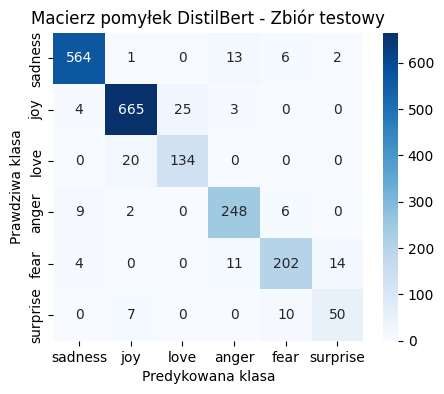

In [25]:
plot_confusion_matrix(classes_predicted, predictions.label_ids, title="Macierz pomyłek DistilBert - Zbiór testowy")

#### Na zbiorze treningowym


In [26]:
predictions = trainer.predict(tokenized_train_dataset)
classes_predicted = np.argmax(predictions.predictions, axis=-1)

In [27]:
print_classification_report(predictions.label_ids, classes_predicted)

              precision    recall  f1-score   support

 sadness (0)       0.98      0.99      0.99      4666
     joy (1)       0.97      0.97      0.97      5362
    love (2)       0.91      0.89      0.90      1304
   anger (3)       0.97      0.96      0.97      2159
    fear (4)       0.94      0.95      0.94      1937
surprise (5)       0.85      0.89      0.87       572

    accuracy                           0.96     16000
   macro avg       0.94      0.94      0.94     16000
weighted avg       0.96      0.96      0.96     16000



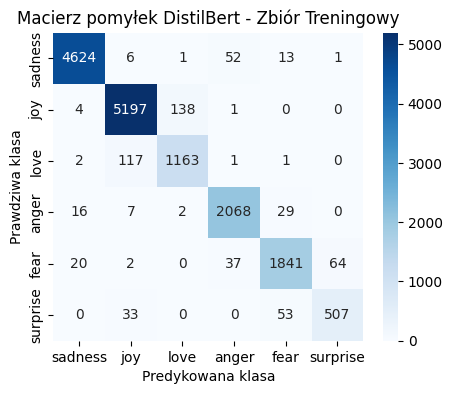

In [28]:
plot_confusion_matrix(classes_predicted, predictions.label_ids, title="Macierz pomyłek DistilBert - Zbiór Treningowy")

### Wizualizacja wyznaczonych reprezentacji (dla części zbioru testowego) metodą UMAP.

In [29]:
def compute_emb(tokenized_text, model, device):
    tokenized_text = torch.tensor(tokenized_text).unsqueeze(0).to(device)
    with torch.inference_mode():
        outputs = model(tokenized_text)
        text_embedding = outputs.last_hidden_state[:, 0].squeeze(0)
        return text_embedding

In [30]:
def compute_embeddings(model, device):
    bert_model = model.distilbert
    bert_model.eval()

    embeddings = None
    class_labels = []

    for i in tqdm(range(len(tokenized_test_dataset))):
        class_labels.append(tokenized_test_dataset[i]['label'])
        embedding = compute_emb(tokenized_test_dataset[i]['input_ids'], bert_model, device)
        embedding = embedding.detach().cpu().numpy()
        if embeddings is None:
            embeddings = np.zeros((len(tokenized_test_dataset), embedding.shape[0]), dtype=embedding.dtype)
        else:
            embeddings[i] = embedding

    return embeddings, class_labels

In [31]:
embeddings, class_labels = compute_embeddings(dbert_model, device)
print(f"\nRozmiar wektorów reprezentacji: {embeddings.shape[1]}")

100%|██████████| 2000/2000 [00:32<00:00, 61.17it/s]


Rozmiar wektorów reprezentacji: 768


In [32]:
df_umap = gen_df_umap(embeddings, class_labels)

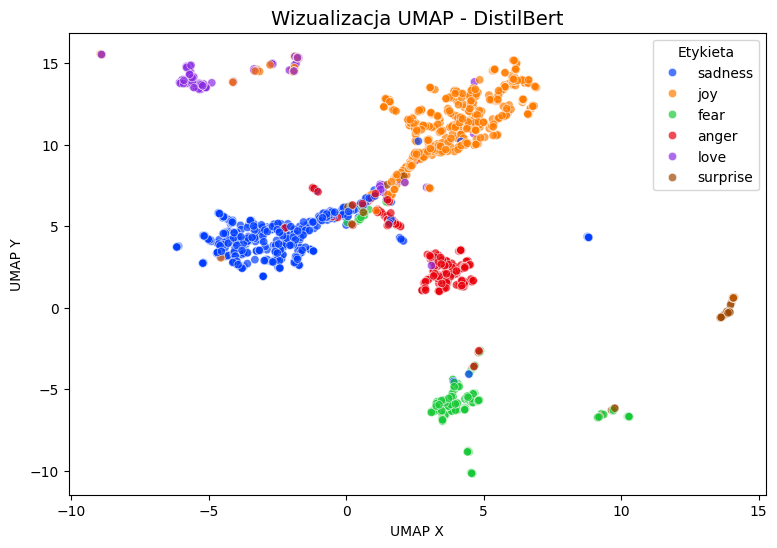

In [33]:
plot_umap(df_umap, "Wizualizacja UMAP - DistilBert")

## Podejście 3 - Dostosowanie modelu generatywnego (klasy tylko-dekoder) do generowania odpowiedzi w oczekiwanym formacie.

### Tokenizator i Model bazowy

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [15]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

quantization_config = BitsAndBytesConfig(load_in_8bit=True)

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B-Base")
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3-1.7B-Base", quantization_config=quantization_config)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

In [16]:
# TEST MODELU
input_text = "Write me a poem about Machine Learning."
input_ids = tokenizer(input_text, return_tensors="pt").to(device)

outputs = model.generate(**input_ids, max_new_tokens=20)
print(tokenizer.decode(outputs[0]))


Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Write me a poem about Machine Learning. **The Algorithmic Symphony**  

In the heart of the digital realm,  
Where data flows like


### Funkcje pomocnicze - podejście 3

In [17]:
from colorama import Fore
from transformers import BatchEncoding


def generate_text(model: torch.nn.Module, model_input: BatchEncoding, max_new_tokens: int = 100,
                  return_full_text: bool = False) -> str:

  model.eval()
  with torch.inference_mode():
    generated_tokens = model.generate(
        input_ids = model_input['input_ids'],
        attention_mask = model_input['attention_mask'],
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        max_new_tokens=max_new_tokens,
        num_beams=1,
        do_sample=False)[0]
    if not return_full_text:
      generated_tokens = generated_tokens[model_input['input_ids'].shape[1]:]
    return tokenizer.decode(generated_tokens, skip_special_tokens=True)


def generate_and_print_text(model: torch.nn.Module, prompt: str, tokenizer, max_new_tokens: int = 100):
  model_input = tokenizer(prompt, return_tensors="pt").to(device)
  generated_text = generate_text(model, model_input, max_new_tokens)
  print(f"{Fore.BLACK}{prompt}", end="")
  print(f"{Fore.CYAN}{generated_text}")

In [18]:
def tokenize_with_padding(prompt, max_length: int):
    result = tokenizer(prompt, truncation=True, max_length=max_length, padding="max_length")
    result["labels"] = result["input_ids"].copy()
    return result

In [19]:
INSTRUCTION = (
    f"Your task is to analyze emotions in text. "
    f"Assign one of these 6 emotions: {LABELS} to the following text. "
    "Answer only with one word from emotions list."
    )


def train_prompt_with_instruction(data_point) -> str:
    prompt=f"""{INSTRUCTION}
## Input Text:
{data_point["text"]}
## Assigned emotion:
{LABEL_MAP[data_point["label"]]} {tokenizer.eos_token}"""
    return prompt

def test_prompt_with_instruction(data_point) -> str:
    prompt=f"""{INSTRUCTION}
## Input Text:
{data_point["text"]}
## Assigned emotion:
"""
    return prompt

In [20]:
import random
random.seed(42)

def create_test_prompt_with_demonstration(data_point, n_examples: int) -> str:
    prompt = ""
    for i in range(n_examples):
        example = random.choice(train_dataset) # examples are taken from train_dataset
        prompt += train_prompt_with_instruction(example)
        prompt += "\n"
    prompt += test_prompt_with_instruction(data_point)
    return prompt

In [21]:
from torch.utils.data import DataLoader

def get_qwen_preds_batched(model, tokenizer, dataset, batch_size=8, n_examples=3):
    model.eval()
    all_preds = []
    all_targets = []
    all_embeddings = []

    loader = DataLoader(dataset, batch_size=batch_size)

    for batch in tqdm(loader):
        texts = batch['text']
        targets = batch['label']


        prompts = [create_test_prompt_with_demonstration({"text": t}, n_examples=n_examples) for t in texts]

        inputs = tokenizer(prompts, return_tensors="pt", padding=True, padding_side='left', truncation=True).to(model.device)

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                return_dict_in_generate=True,
                output_hidden_states=True,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

            input_len = inputs.input_ids.shape[1]
            generated_tokens = outputs.sequences[:, input_len:]
            batch_preds_text = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)

            last_layer_hidden_states = outputs.hidden_states[0][-1]
            batch_embeddings = last_layer_hidden_states[:, -1, :].detach().cpu().numpy()

        for text in batch_preds_text:
            words = text.strip().split()
            first_word = words[0].lower() if words else ""

            pred_id = -1
            for id, label in LABEL_MAP.items():
                if first_word == label.lower():
                    pred_id = id
                    break
            all_preds.append(pred_id)

        all_targets.extend(targets.numpy())
        all_embeddings.append(batch_embeddings)

        del inputs, outputs

    return np.array(all_targets), np.array(all_preds), np.vstack(all_embeddings)

### Few-shot prompting

#### Sprawdzenie różnych ilości przykładów

In [ ]:
item_id = 39
print(f"{test_dataset[item_id]["text"]} ---> {LABEL_MAP[test_dataset[item_id]["label"]]}")

i had been talking to coach claudia barcomb and coach ali boe for a long time and they both made me feel very welcomed at union ---> joy


In [ ]:
s = test_prompt_with_instruction(test_dataset[item_id])
generate_and_print_text(model, s, tokenizer, max_new_tokens=7)

Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i had been talking to coach claudia barcomb and coach ali boe for a long time and they both made me feel very welcomed at union
## Assigned emotion:
joy


In [ ]:
s = create_test_prompt_with_demonstration(test_dataset[item_id], 1)
generate_and_print_text(model, s, tokenizer, max_new_tokens=7)

Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i do find new friends i m going to try extra hard to make them stay and if i decide that i don t want to feel hurt again and just ride out the last year of school on my own i m going to have to try extra hard not to care what people think of me being a loner
## Assigned emotion:
sadness <|endoftext|>
Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i had been talking to coach claudia barcomb and coach ali boe for a long time and they both made me feel very welcomed at union
## Assigned emotion:
joy 1


In [ ]:
s = create_test_prompt_with_demonstration(test_dataset[item_id], 5)
generate_and_print_text(model, s, tokenizer, max_new_tokens=7)

Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i asked them to join me in creating a world where all year old girls could grow up feeling hopeful and powerful
## Assigned emotion:
joy <|endoftext|>
Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i feel when you are a caring person you attract other caring people into your life
## Assigned emotion:
love <|endoftext|>
Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i sometimes feel so vulnerable and so lost
## Assigned emotion:
fear <|endoftext|>
Your task is 

#### Wyznaczenie metryk

##### Na zbiorze testowym

In [22]:
y_true_test, y_pred_test, embeddings_test = get_qwen_preds_batched(model, tokenizer, test_dataset, batch_size=16, n_examples=3)


100%|██████████| 125/125 [08:08<00:00,  3.91s/it]


Model poprawnie sformatował odpowiedź w 1997/2000 przypadkach.
              precision    recall  f1-score   support

 sadness (0)       0.73      0.38      0.50       580
     joy (1)       0.69      0.68      0.68       694
    love (2)       0.38      0.23      0.29       159
   anger (3)       0.47      0.49      0.48       274
    fear (4)       0.35      0.36      0.36       224
surprise (5)       0.09      0.56      0.16        66

    accuracy                           0.49      1997
   macro avg       0.45      0.45      0.41      1997
weighted avg       0.59      0.49      0.52      1997



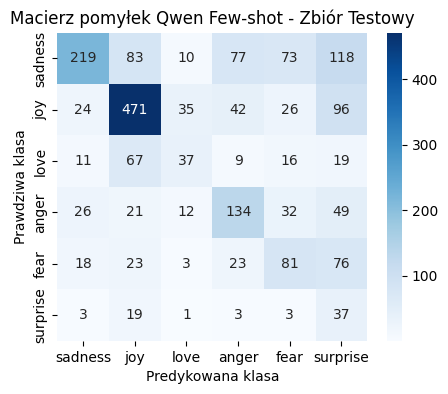

In [23]:
valid_mask = y_pred_test != -1
print(f"Model poprawnie sformatował odpowiedź w {valid_mask.sum()}/{len(y_pred_test)} przypadkach.")

print_classification_report(y_true_test[valid_mask], y_pred_test[valid_mask])
plot_confusion_matrix(y_true_test[valid_mask], y_pred_test[valid_mask], title="Macierz pomyłek Qwen Few-shot - Zbiór Testowy")

#### Wizualizacja wyznaczonych reprezentacji (dla części zbioru testowego) metodą UMAP.

In [24]:
df_umap = gen_df_umap(embeddings_test, y_pred_test)

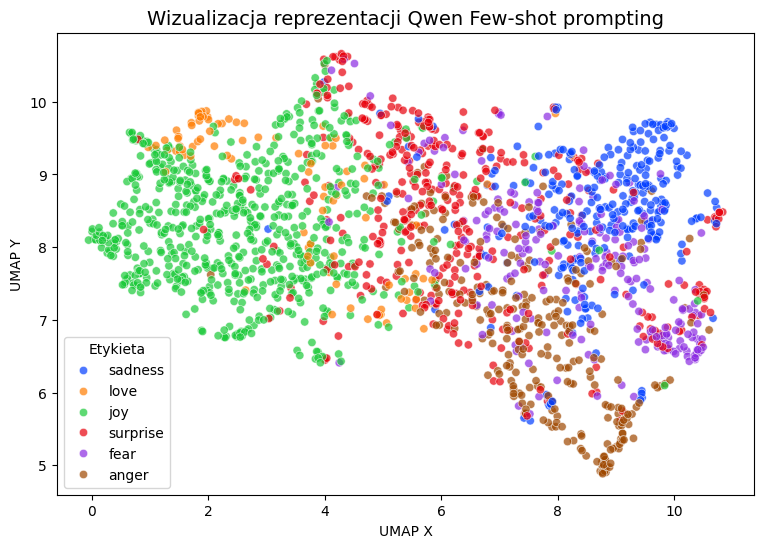

In [25]:
plot_umap(df_umap, title="Wizualizacja reprezentacji Qwen Few-shot prompting")

### LoRA

In [ ]:
print(model)

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear8bitLt(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear8bitLt(in_features=2048, out_features=1024, bias=False)
          (v_proj): Linear8bitLt(in_features=2048, out_features=1024, bias=False)
          (o_proj): Linear8bitLt(in_features=2048, out_features=2048, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear8bitLt(in_features=2048, out_features=6144, bias=False)
          (up_proj): Linear8bitLt(in_features=2048, out_features=6144, bias=False)
          (down_proj): Linear8bitLt(in_features=6144, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((2048,)

In [ ]:
def generate_and_tokenize_train_prompt_with_padding(dataset_item):
    max_length = 400
    return tokenize_with_padding(train_prompt_with_instruction(dataset_item), max_length)

tokenized_train_dataset = train_dataset.map(generate_and_tokenize_train_prompt_with_padding)
tokenized_val_dataset = val_dataset.map(generate_and_tokenize_train_prompt_with_padding)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
import copy
from peft import LoraConfig, get_peft_model, TaskType

config = LoraConfig(r=8, lora_alpha=32, target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"], task_type=TaskType.CAUSAL_LM)
peft_model = get_peft_model(copy.deepcopy(model), config)

In [ ]:
import os
os.environ["WANDB_LOG_MODEL"] = "checkpoint"

In [ ]:
from transformers import Trainer, TrainingArguments, DataCollatorForLanguageModeling

args = TrainingArguments(
    output_dir="./qwen-lora",
    warmup_steps=3,
    per_device_train_batch_size=3,
    gradient_accumulation_steps=2,
    max_steps=400,
    learning_rate=2.5e-5,
    optim="paged_adamw_8bit",
    logging_dir="./qwen-lora-logs",
    logging_steps = 100,
    eval_strategy="steps",
    eval_steps=50,
    do_eval=True,
    save_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    report_to="wandb"
)

trainer = Trainer(
    model=peft_model,
    train_dataset=tokenized_train_dataset,
    eval_dataset=tokenized_val_dataset,
    args=args,
    data_collator=DataCollatorForLanguageModeling(tokenizer, mlm=False)
)


In [ ]:
peft_model.config.use_cache = False
trainer.train()
peft_model.config.use_cache = True

In [29]:
peft_model.eval()
for i in range(7, 10):
    data = test_dataset[i]
    print(f"{Fore.RED}NIEDOSTROJONA WERSJA MODELU")
    prompt = test_prompt_with_instruction(data)
    generate_and_print_text(model, prompt, tokenizer, max_new_tokens=10)
    print(f"{Fore.RED}{'-'*80}")
    print(f"{Fore.RED}DOSTROJNA WERSJA MODELU")
    prompt = test_prompt_with_instruction(data)
    generate_and_print_text(peft_model, prompt, tokenizer, max_new_tokens=10)
    print(f"{Fore.RED}{'-'*80}")

NIEDOSTROJONA WERSJA MODELU
Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepted into the masters program at the university of virginia
## Assigned emotion:
sadness
--------------------------------------------------------------------------------
DOSTROJNA WERSJA MODELU
Your task is to analyze emotions in text. Assign of these 6 emotions: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'] to the following text. Answer only with one word from emotions list.
## Input Text:
i explain why i clung to a relationship with a boy who was in many ways immature and uncommitted despite the excitement i should have been feeling for getting accepted into the masters program at

#### Wyznaczenie metryk

###### Na zbiorze testowym

In [30]:
y_true_test, y_pred_test, embeddings_test = get_qwen_preds_batched(peft_model, tokenizer, test_dataset, n_examples=0)

100%|██████████| 250/250 [11:15<00:00,  2.70s/it]


Model poprawnie sformatował odpowiedź w 1999/2000 przypadkach.
              precision    recall  f1-score   support

 sadness (0)       0.61      0.78      0.68       581
     joy (1)       0.72      0.81      0.76       694
    love (2)       0.47      0.22      0.30       159
   anger (3)       0.66      0.49      0.56       275
    fear (4)       0.60      0.51      0.55       224
surprise (5)       0.00      0.00      0.00        66

    accuracy                           0.65      1999
   macro avg       0.51      0.47      0.48      1999
weighted avg       0.62      0.65      0.63      1999



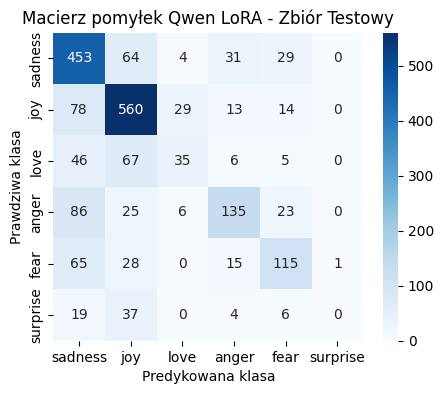

In [34]:
valid_mask = y_pred_test != -1
print(f"Model poprawnie sformatował odpowiedź w {valid_mask.sum()}/{len(y_pred_test)} przypadkach.")

print_classification_report(y_true_test[valid_mask], y_pred_test[valid_mask])
plot_confusion_matrix(y_true_test[valid_mask], y_pred_test[valid_mask], title="Macierz pomyłek Qwen LoRA - Zbiór Testowy")

###### Na zbiorze treningowym

In [35]:
y_true_train, y_pred_train, embeddings_train = get_qwen_preds_batched(peft_model, tokenizer, train_dataset, n_examples=0)

100%|██████████| 2000/2000 [1:23:32<00:00,  2.51s/it]


Model poprawnie sformatował odpowiedź w 15994/16000 przypadkach.
              precision    recall  f1-score   support

 sadness (0)       0.61      0.78      0.69      4666
     joy (1)       0.68      0.78      0.73      5357
    love (2)       0.48      0.22      0.30      1304
   anger (3)       0.69      0.54      0.61      2158
    fear (4)       0.64      0.52      0.57      1937
surprise (5)       0.96      0.04      0.08       572

    accuracy                           0.65     15994
   macro avg       0.68      0.48      0.50     15994
weighted avg       0.65      0.65      0.62     15994



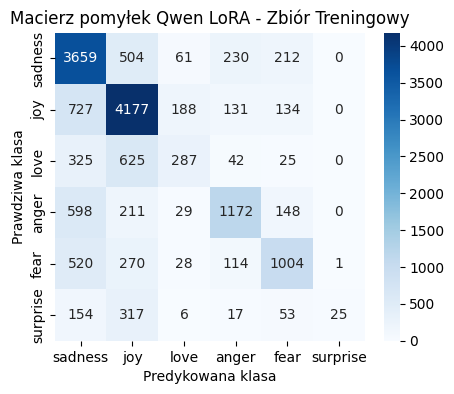

In [36]:
valid_mask = y_pred_train != -1
print(f"Model poprawnie sformatował odpowiedź w {valid_mask.sum()}/{len(y_pred_train)} przypadkach.")

print_classification_report(y_true_train[valid_mask], y_pred_train[valid_mask])
plot_confusion_matrix(y_true_train[valid_mask], y_pred_train[valid_mask], title="Macierz pomyłek Qwen LoRA - Zbiór Treningowy")

#### Wizualizacja wyznaczonych reprezentacji (dla części zbioru testowego) metodą UMAP.

In [31]:
df_umap = gen_df_umap(embeddings_test, y_pred_test)

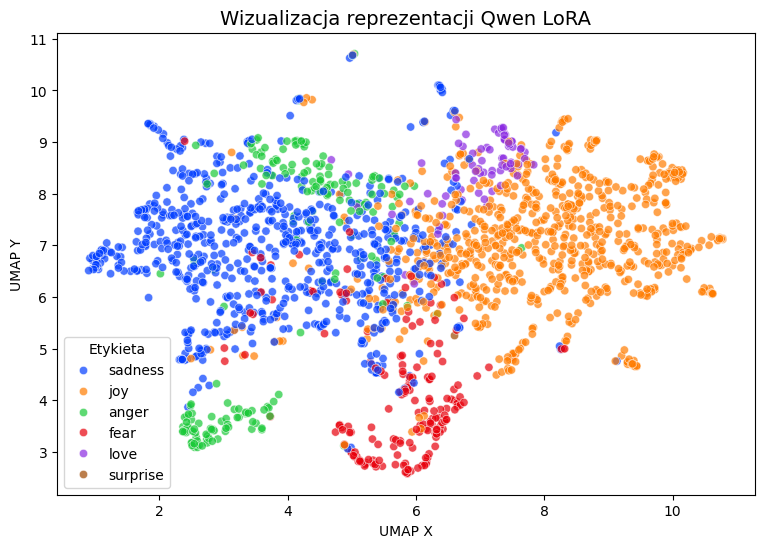

In [32]:
plot_umap(df_umap, title="Wizualizacja reprezentacji Qwen LoRA")